# Supervised cold start

**Notebook 03 · Learn from worked solutions before learning from your own mistakes**

A small, complete supervised fine-tuning experiment for `Qwen/Qwen3-0.6B-Base`.
We prepare separate practice and validation questions, inspect exactly which tokens
contribute to the loss, train briefly, evaluate, and save a reusable checkpoint.

| Experiment | Fixed starting choice |
| :--- | :--- |
| Student | Original pinned `Qwen/Qwen3-0.6B-Base` checkpoint from 02 |
| Teaching material | 256 GSM8K reference solutions from the **train** split |
| Validation | 64 separate questions from that same train split |
| Reserved test | The 32 fixed test questions from 02, evaluated only after training |
| Update | Full student fine-tuning, one epoch; no teacher, LoRA, or KL |
| Saved execution | Completed A100 training run: 256 practice examples, 32 optimizer steps |
| Research status | Educational adaptation; strong format learning, mixed task results |

**Read in order:** [1. Goal](#goal) · [2. Data](#data) · [3. Tensors and loss](#tensors) ·
[4. Starting point](#starting) · [5. Training](#training) · [6. Evaluation](#evaluation) ·
[7. Save and recap](#save)

> The saved outputs show the author's completed A100 training run. Local QA runs
> `inspect` mode separately and does not replace these outputs. To repeat training,
> use a fresh Colab GPU runtime and `MODE = "train"`. You do not need to run 01 or 02 first. Download results before
> disconnecting; this project does not use Google Drive.

---
<a id="goal"></a>
## 1. Understand the goal

> **Goal:** Teach the student what a worked answer looks like, including its final line.

In 02, no original response followed the requested `#### <number>` format.
A **cold start** gives the student some practice before the later distillation stage.
Here, the practice comes from existing reference solutions, not a teacher model.

For example:

```text
Question: A box has 3 red pencils and 2 blue pencils. How many pencils are there?
Reference response: There are 3 + 2 = 5 pencils.
#### 5
```

During supervised fine-tuning (**SFT**), the student learns to predict the response
one token at a time while reading the correct preceding tokens. This is called
**teacher forcing**, even though we do not load a teacher model. The term refers
to supplying the known preceding tokens, not who originally wrote the solution.

In later on-policy distillation, the student will write its own response first,
and a frozen teacher will score those student-written prefixes. This notebook
only builds the supervised starting point.

![Reference-solution SFT workflow](assets/03_sft_cold_start/sft_workflow.png)

*Figure 1. Worked solutions supply targets; only the student's weights change.*
[SVG](assets/03_sft_cold_start/sft_workflow.svg)

The [GKD paper, Section 4.3](https://arxiv.org/html/2306.13649v3#S4.SS3) starts
arithmetic distillation from supervised-fine-tuned models. Its setup used different
models and generated solutions. Our small reference-solution experiment follows
the staging idea, not the paper's exact training recipe or reported scores.

### 1.1 Choose inspection or training

`inspect` downloads only the pinned tokenizer and dataset, then checks real examples.
It does not load the 0.6B weights or produce model performance numbers.
`train` runs the full experiment on CUDA. The defaults are deliberately small;
a successful run does not guarantee an accuracy gain.

Colab installs dependencies with `uv` into the selected kernel. If installation
changes libraries, the cell stops and asks for a restart. Restart, then run from
the top. This prevents the mixed-version pandas/Matplotlib errors encountered in 02.
The existing PyTorch/CUDA installation is preserved.

In [1]:
import importlib.metadata
import importlib.util
import os
import subprocess
import sys
import tempfile
from pathlib import Path

# Change to "train" for a real student training run on your Colab GPU.
# Automated local validation explicitly selects "inspect" instead.
MODE = os.environ.get("OPD_SFT_MODE", "train")
if MODE not in {"inspect", "train"}:
    raise ValueError("Choose MODE='inspect' or MODE='train'.")
IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False

# A remote kernel reads files on Colab's server, not your local VS Code folder.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "src/baseline.py").is_file()), None)
if PROJECT_ROOT is None:
    if not IN_COLAB:
        raise RuntimeError("Open Jupyter inside the project checkout.")
    PROJECT_ROOT = Path("/content/on-policy-distillation")
    if not PROJECT_ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", "dev",
                        "https://github.com/igoldin670/on-policy-distillation.git",
                        str(PROJECT_ROOT)], check=True)
# An existing Colab checkout may predate this notebook. Fast-forward it only
# when the required helper is missing; Git refuses to overwrite conflicting edits.
if IN_COLAB and not (PROJECT_ROOT / "src/sft.py").is_file():
    subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only", "origin", "dev"], check=True)
if not (PROJECT_ROOT / "src/sft.py").is_file():
    raise RuntimeError("This runtime checkout predates 03. Sync the complete project, including src/sft.py, before running.")

if IN_COLAB:
    # Install before importing data/model libraries; never replace Colab's torch.
    packages = [line.strip() for line in (PROJECT_ROOT / "requirements-generation.txt").read_text().splitlines()
                if line.strip() and not line.lstrip().startswith("#")]
    packages += [line.strip() for line in (PROJECT_ROOT / "requirements-notebook.txt").read_text().splitlines()
                 if line.split("==")[0] in {"numpy", "pandas", "matplotlib"}]
    packages += ["bottleneck==1.5.0", "ipywidgets==8.1.8"]
    changed = []
    for requirement in packages:
        name, version = requirement.split("==")
        try:
            installed = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            installed = None
        loaded = sys.modules.get(name)
        if loaded is not None and getattr(loaded, "__version__", installed) != installed:
            raise RuntimeError(f"Restart the Colab kernel: {name} has mixed loaded/installed versions.")
        if installed != version:
            changed.append(requirement)
    if changed:
        if importlib.util.find_spec("uv") is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "uv"], check=True)
        subprocess.run([sys.executable, "-m", "uv", "pip", "install", "--python", sys.executable, *packages], check=True)
        raise RuntimeError("Dependencies installed. Restart the Colab kernel and run from the top.")

# Keep caches writable and public downloads separate from Colab's secrets vault.
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "opd-matplotlib"))
os.environ.setdefault("HF_HOME", str(PROJECT_ROOT / ".cache/source-verification"))
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print(f"Mode: {MODE} | Colab: {IN_COLAB} | Project: {PROJECT_ROOT}")

Mode: train | Colab: True | Project: /content/on-policy-distillation


In [2]:
import json
import math
import random
import shutil
import time
from dataclasses import asdict

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import load_dataset, disable_progress_bars
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, get_linear_schedule_with_warmup

from src.baseline import verify_recorded_run
from src.sft import (
    SFTConfig, backward_group, collate_examples, evaluation_summary,
    generate_evaluation, new_run_directory, prepare_splits, save_checkpoint,
    save_report, training_groups, validation_loss, verify_checkpoint, verify_report, write_json,
)

# Reuse the immutable protocol, not notebook 02's live Python variables.
# This pins the model, tokenizer, questions, prompt template, and generation settings.
baseline_run = verify_recorded_run(PROJECT_ROOT / "notebooks/assets/02_baseline_evaluation/recorded_run")
protocol = baseline_run["manifest"]["protocol"]
config = SFTConfig()
random.seed(config.seed)
torch.manual_seed(config.seed)
disable_progress_bars()
print("Configuration:", asdict(config))
print("Student:", protocol["student_model_id"], "| revision:", protocol["student_revision"])
print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())

Configuration: {'seed': 42, 'train_examples': 256, 'validation_examples': 64, 'max_sequence_length': 1024, 'epochs': 1, 'microbatch_size': 1, 'accumulation_steps': 8, 'learning_rate': 2e-05, 'weight_decay': 0.01, 'max_grad_norm': 1.0, 'warmup_fraction': 0.1, 'validation_interval': 8}
Student: Qwen/Qwen3-0.6B-Base | revision: da87bfb608c14b7cf20ba1ce41287e8de496c0cd
PyTorch: 2.11.0+cu130 | CUDA available: True


---
<a id="data"></a>
## 2. Prepare practice and validation data

> **Goal:** Learn from practice questions while keeping the exam separate.

We select 256 practice examples and 64 validation examples from GSM8K's **train**
split. Validation is a small progress check; its answers never enter an optimizer
update. The 32 test questions from 02 remain a separate final measurement.

The seed makes the selection repeatable. We also exclude duplicate questions and
normalized text overlap with the reserved test set. A split name alone is not a
substitute for checking the actual question text.

GSM8K solutions contain calculator markup such as `<<3+2=5>>5`. We remove the
`<<...>>` annotation and keep the visible `5`, the written reasoning, and the
final `#### 5` line. We do not replace reference solutions with generated answers.

In [3]:
# Public, pinned sources need no Hugging Face token or teacher weights.
tokenizer = AutoTokenizer.from_pretrained(protocol["student_model_id"],
                                         revision=protocol["student_revision"], token=False)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
# Right padding keeps response positions unchanged in a training batch.
tokenizer.padding_side = "right"
source_train = load_dataset(protocol["dataset_id"], protocol["dataset_config"],
                            split="train", revision=protocol["dataset_revision"], token=False)
splits = prepare_splits(source_train, tokenizer, protocol, config)
train_examples = splits["train"]
validation_examples = splits["validation"]
print(f"Selected {len(train_examples)} training and {len(validation_examples)} validation examples.")
print(f"Recorded {len(splits['exclusions'])} exclusions while scanning the seeded candidate order.")
if splits["exclusions"]:
    display(pd.DataFrame(splits["exclusions"]).groupby("reason").size().rename("excluded").to_frame())

# Display a real training example, not a reserved test answer.
example = train_examples[0]
print("QUESTION:\n", example["question"])
print("\nCLEANED REFERENCE RESPONSE:\n", example["target_text"])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Selected 256 training and 64 validation examples.
Recorded 0 exclusions while scanning the seeded candidate order.
QUESTION:
 Stefan goes to a restaurant to eat dinner with his family. They order an appetizer that costs $10 and 4 entrees that are $20 each. If they tip 20% of the total for the waiter, what is the total amount of money that they spend at the restaurant?

CLEANED REFERENCE RESPONSE:
 The total cost of the entrees is 4 * $20 = $80.
The total cost of the dinner is $80 + $10 = $90.
The tip is $90 * 0.20 = $18
The total cost with tip is $90 + $18 = $108
#### 108


### Checkpoint: the practice set is fixed

The split helper returns exact example IDs and records every skipped candidate.
Examples longer than 1,024 complete tokens are skipped, not shortened: cutting a
solution could remove its final answer. Invalid references and unstable tokenizer
boundaries are also recorded rather than accepted silently.

The selected tokenizer and raw dataset are downloaded to the runtime's cache.
The student weights have still not been loaded. The full selected examples and
encoded targets will be included in the training report.

---
<a id="tensors"></a>
## 3. Build training tensors and understand the loss

> **Goal:** Make the student learn response tokens, not copy questions or padding.

A training example is **prompt + reference response + end token**. Three tensors
have shape `[batch_size, sequence_length]`:

| Tensor | Purpose |
| :--- | :--- |
| `input_ids` | Token IDs the student reads |
| `attention_mask` | 1 for real input positions, 0 for added padding |
| `labels` | Response token IDs; `-100` for prompt and padding positions |

`-100` means “ignore this target in cross-entropy.” It is not a token we feed to
the model. Prompt tokens still provide context; they simply do not earn a loss.

![Response labels and padding positions](assets/03_sft_cold_start/response_mask.png)

*Figure 2. An illustrative short sequence, not the actual tokenizer's word boundaries.*
[SVG](assets/03_sft_cold_start/response_mask.svg)

### A slower walkthrough: what are we teaching the student?

Section 3 prepares the model's practice exercise. It answers three questions:

1. What does the student read?
2. Which tokens should it learn to predict?
3. How do we measure how well it predicted them?

#### Start with one small example

```text
Question: What is 3 + 2?
Answer: 3 + 2 equals 5.
#### 5
```

The question and instructions are the **prompt**. The worked solution and final
answer are the **reference response**. The response comes from the dataset;
the student has not generated it.

The tokenizer converts the text into numbers called **token IDs**. Tokens can be
words, word pieces, punctuation, or whitespace. For this explanation, imagine
these five illustrative tokens, rather than the actual tokenization above:

```text
[Prompt A] [Prompt B] [Answer A] [Answer B] [END]
```

#### Three tensors, three jobs

A **tensor** here is an organized table of numbers. Each row holds one example.

| Position | Prompt A | Prompt B | Answer A | Answer B | END |
| :--- | :--- | :--- | :--- | :--- | :--- |
| `input_ids` | Its token ID | Its token ID | Its token ID | Its token ID | End-token ID |
| `attention_mask` | 1 | 1 | 1 | 1 | 1 |
| `labels` | -100 | -100 | Answer A ID | Answer B ID | End-token ID |

`input_ids` contains what the student reads. The `attention_mask` distinguishes
real input from padding. `labels` tells the loss function which tokens to score.

**`-100` means "ignore this target when calculating loss."** It is not a token
fed into the model. The prompt still provides context, but predicting the prompt
itself is not the exercise. We want to teach the student to answer the question.

#### Why the prediction and target are one position apart

A language model predicts **what comes next**:

| After reading through… | The model predicts… | Include in this loss? |
| :--- | :--- | :--- |
| Prompt A | Prompt B | No |
| Prompt B | Answer A | Yes |
| Answer A | Answer B | Yes |
| Answer B | END | Yes |

The most important boundary is **final prompt token → first answer token**.
If the prompt has eight tokens, the first response token is at index 8, but its
predicting logits are at index 7. Positions start at zero.

**Logits** are raw scores for possible next tokens. We align predictions and
correct targets using:

```python
logits[:, :-1, :]  # Predictions, excluding the final position.
labels[:, 1:]     # Targets, excluding the first position.
```

The last prediction has no following stored token to check. The first stored
token has no earlier prediction in this sequence. This alignment happens
**exactly once** in our loss helper.


In [4]:
# Batch two real examples so we can inspect unequal lengths and padding.
preview_examples = train_examples[:2]
preview_batch = collate_examples(preview_examples, tokenizer.pad_token_id)
print({name: tuple(tensor.shape) for name, tensor in preview_batch.items()})

# The first response ID sits at prompt_length in input_ids. Its predicting logits
# will be at prompt_length - 1. The table makes this boundary easy to inspect.
prompt_length = example["prompt_length"]
positions = sorted(set(range(max(0, prompt_length - 2), min(prompt_length + 4, len(example["input_ids"]))))
                  | {len(example["input_ids"]) - 1})
display(pd.DataFrame([{
    "position": position,
    "role": "prompt" if position < prompt_length else "EOS" if position == len(example["input_ids"]) - 1 else "response",
    "token": repr(tokenizer.decode([example["input_ids"][position]])),
    "label": example["labels"][position],
    "predicting_logits_position": position - 1,
} for position in positions]))

for row_index, record in enumerate(preview_examples):
    length, boundary = len(record["input_ids"]), record["prompt_length"]
    assert (preview_batch["labels"][row_index, :boundary] == -100).all()
    assert preview_batch["labels"][row_index, length - 1].item() == tokenizer.eos_token_id
    assert (preview_batch["labels"][row_index, length:] == -100).all()
    assert (preview_batch["attention_mask"][row_index, length:] == 0).all()
    assert int((preview_batch["labels"][row_index, 1:] != -100).sum()) == record["target_length"]
print("Prompt/response alignment, real end tokens, and padding checks passed.")

{'input_ids': (2, 195), 'attention_mask': (2, 195), 'labels': (2, 195)}


,position,role,token,label,predicting_logits_position
0,89,prompt,'Answer',-100,88
1,90,prompt,':\n',-100,89
2,91,response,'The',785,90
3,92,response,' total',2790,91
4,93,response,' cost',2783,92
5,94,response,' of',315,93
6,170,EOS,'<|endoftext|>',151643,169


Prompt/response alignment, real end tokens, and padding checks passed.


### Cross-entropy: how surprising was the correct token?

Suppose the correct next token is `5`. In a made-up three-token vocabulary,
the student assigns these probabilities:

```text
5 → 10%
6 → 70%
7 → 20%
```

The student strongly prefers the wrong choice. Cross-entropy gives a larger loss
when the probability assigned to the correct token is smaller. For one known
correct target, the calculation is:

```text
loss = -log(probability assigned to the correct token)
```

| Probability of the correct token | Loss | Interpretation |
| :--- | ---: | :--- |
| 90% | 0.105 | The correct token was expected |
| 50% | 0.693 | It was less certain |
| 10% | 2.303 | The correct token was surprising |

These numbers are illustrations, not Qwen measurements. We use natural logarithms,
so the loss is measured in nats. **Higher probability for the correct token means
lower loss.** PyTorch's cross-entropy function accepts raw logits and performs
the log-probability calculation internally; we do not apply softmax first.

Suppose three included response tokens have losses `0.2`, `0.8`, and `0.5`.
Their average is `(0.2 + 0.8 + 0.5) / 3 = 0.5`. Prompt positions marked `-100`
do not enter this average.

During training, PyTorch calculates **gradients**, which describe how the weights
affect this loss. The optimizer uses those gradients to adjust the weights toward
reducing it. Section 3 prepares and checks this exercise; the weight updates come
later in Section 5.

### Padding is filler; the end token is part of the answer

Examples can have different lengths. Padding makes them fit into a rectangular tensor:

```text
Example 1: [Prompt] [Answer A] [Answer B] [END]
Example 2: [Prompt] [Answer A] [END]      [PAD]
```

For the second example, the masks and targets are:

```text
Attention mask:   1         1        1        0
Labels:         -100    Answer A    END     -100
```

We include END so the student can learn when to stop. We exclude PAD because
it is artificial filler. Our tokenizer can use the same ID for END and PAD,
so we distinguish them by **position**, not by ignoring every occurrence of that ID.

### 3.1 One prediction shift, one response-only objective

The logits after position $j$ predict the token at $j+1$. For an eight-token
prompt, the first response token is at index 8 and its predicting logits are at
index 7. We align them with `logits[:, :-1, :]` and `labels[:, 1:]`.

Let $R$ be the included response-target positions across an optimizer group,
including real end tokens. The loss is their average negative log probability:

$$
\mathcal{L}_{\mathrm{SFT}}
= -\frac{1}{|R|}\sum_{(i,t)\in R}\log p_\theta(y_{i,t}\mid x_i,y_{i,<t}).
$$

In simple terms: **make the correct next response token less surprising**. If the
model assigns the correct token probability 0.25, its loss is `-log(0.25)`, about
1.386. A probability of 0.5 gives a smaller loss, about 0.693. These are invented
numbers for explaining the math, not measured model scores.

The helper converts logits to FP32 before cross-entropy, ignores `-100`, and
returns a **sum and token count**. We divide by the number of included tokens.
We apply the shift ourselves and do not also pass `labels` into the model, which
would risk applying the shift twice. Unit tests compare this with Hugging Face's
built-in shifted loss.

### 3.2 Why accumulate gradients?

We process one example at a time to save GPU memory. Eight small forward/backward
passes contribute to one optimizer update. The graphs are freed after each pass.
If two microbatches have 2 and 6 response tokens, each token should have weight
`1/8`, rather than giving the two batches equal weight. `backward_group` divides
each summed loss by the **whole group's** target count. It also handles a smaller
last group correctly.

**Checkpoint:** all data checks can run on CPU. They prove which targets will
contribute to training, not that any model has learned yet.

### What Section 3 proves

We have checked the right learning task: **read the question, predict the reference
answer one token at a time, and score only the answer and its real stopping token.**
We have not trained the student yet.

During this supervised exercise, the student sees the **correct earlier answer
tokens** when predicting the next one. When generating independently, it must use
its **own** earlier tokens, which may contain mistakes. That is why a lower loss
does not automatically mean better generated answers, and why later sections
measure generation separately.


---
<a id="starting"></a>
## 4. Check the original student's starting point

> **Goal:** Measure the unchanged student before teaching it.

Training mode loads fresh original weights in FP32. **Autocast** uses BF16 for
supported GPU operations, or FP16 with gradient scaling otherwise. It reduces
working memory while keeping parameters and AdamW state in FP32. This is a
single-GPU experiment, not a guarantee that every Colab runtime has enough memory.

Gradient checkpointing saves memory by recomputing some activations during
backward. The training KV cache is disabled because it is useful for generation,
not this full-sequence training pass. No 32B teacher is loaded.

In [5]:
if MODE == "train":
    assert torch.cuda.is_available(), "Training requires CUDA. Use inspect mode on CPU."
    device = torch.device("cuda:0")
    compute_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    torch.cuda.reset_peak_memory_stats()
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory GiB:", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))
    print("Autocast:", compute_dtype, "| parameter storage: FP32")
    student = AutoModelForCausalLM.from_pretrained(
        protocol["student_model_id"], revision=protocol["student_revision"],
        dtype=torch.float32, token=False,
    ).to(device)
    student.config.use_cache = False
    student.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    assert all(p.dtype == torch.float32 for p in student.parameters())
    assert all(p.requires_grad for p in student.parameters())
    run_directory = new_run_directory(PROJECT_ROOT)
    # Save the fixed selection early, so the practice set is inspectable even if interrupted.
    write_json(run_directory / "data_splits.json", splits)
    write_json(run_directory / "configuration.json", asdict(config))
else:
    print("INSPECT: no student weights loaded. Starting-model measurements await train mode.")

GPU: NVIDIA A100-SXM4-80GB
GPU memory GiB: 79.3
Autocast: torch.bfloat16 | parameter storage: FP32


### 4.1 Loss and generated answers tell us different things

Validation loss measures prediction of the **reference solution's tokens**, with
those correct preceding tokens supplied. Generated-answer accuracy asks whether
the student can write a correct answer using **its own** earlier tokens. A lower
validation loss does not guarantee better generated reasoning.

We generate on the same 64 validation questions before and after training, using
02's fixed greedy policy and 512-token budget. The generation helper receives
only each question prompt as input. It never gives the solution to the model.
These paired measurements share this runtime's precision policy. The historical
02 result is useful context, not proof that different runtimes are identical.

In [6]:
# Reference-token loss and question-only generation measure different behaviors.
# Both measurements use validation examples before any optimizer update.
if MODE == "train":
    before_validation_loss = validation_loss(student, validation_examples, tokenizer.pad_token_id, device, compute_dtype)
    before_validation = generate_evaluation(student, tokenizer, validation_examples,
                                            protocol["generation_config"], device, compute_dtype)
    print("Starting validation response NLL:", before_validation_loss)
    display(pd.DataFrame([evaluation_summary(before_validation, "before", "validation")]))
    history = [{"step": 0, "training_loss": None, "validation_loss": before_validation_loss}]
    write_json(run_directory / "before_validation.json", before_validation)
else:
    print("INSPECT: no baseline loss or generated accuracy measured in this execution.")

Evaluating 1/64: gsm8k/train/3370
Evaluating 2/64: gsm8k/train/4852
Evaluating 3/64: gsm8k/train/98
Evaluating 4/64: gsm8k/train/102
Evaluating 5/64: gsm8k/train/1951
Evaluating 6/64: gsm8k/train/6532
Evaluating 7/64: gsm8k/train/5823
Evaluating 8/64: gsm8k/train/930
Evaluating 9/64: gsm8k/train/989
Evaluating 10/64: gsm8k/train/6534
Evaluating 11/64: gsm8k/train/3431
Evaluating 12/64: gsm8k/train/6198
Evaluating 13/64: gsm8k/train/6344
Evaluating 14/64: gsm8k/train/2375
Evaluating 15/64: gsm8k/train/2578
Evaluating 16/64: gsm8k/train/5942
Evaluating 17/64: gsm8k/train/1849
Evaluating 18/64: gsm8k/train/3459
Evaluating 19/64: gsm8k/train/5812
Evaluating 20/64: gsm8k/train/2770
Evaluating 21/64: gsm8k/train/5181
Evaluating 22/64: gsm8k/train/3711
Evaluating 23/64: gsm8k/train/3065
Evaluating 24/64: gsm8k/train/6046
Evaluating 25/64: gsm8k/train/3541
Evaluating 26/64: gsm8k/train/591
Evaluating 27/64: gsm8k/train/6801
Evaluating 28/64: gsm8k/train/1775
Evaluating 29/64: gsm8k/train/4589


,stage,split,questions,strict_accuracy,format_compliance,prose_numeric_accuracy,prose_parse_rate,token_limit_stops
0,before,validation,64,0.0,0.0,0.484375,0.625,0


---
<a id="training"></a>
## 5. Train the student briefly

> **Goal:** Run one fixed, small experiment with visible optimizer updates.

**One epoch** means one pass over the selected 256 practice examples. At a
microbatch size of 1 and eight accumulation steps, this gives 32 optimizer
updates. AdamW adjusts the model's weights. A learning rate of `2e-5` controls
update size; it is a starting choice, not a tuned optimum.

The scheduler warms up over the first 10% of updates, then reduces the learning
rate linearly. Gradient clipping limits the total gradient norm to 1.0. It does
not fix a bad loss: nonfinite losses or gradients stop the run. FP16 gradient
scaling protects small gradients from underflow; BF16 does not need this scaler.

Read the loop as: **clear old gradients → accumulate response loss gradients →
unscale and check → clip → update weights → advance scheduler → record evidence**.
The `backward_group` helper contains the microbatch passes explained in Part 3.

In [7]:
if MODE == "train":
    total_steps = config.epochs * math.ceil(math.ceil(len(train_examples) / config.microbatch_size) / config.accumulation_steps)
    optimizer = torch.optim.AdamW(student.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
    scheduler = get_linear_schedule_with_warmup(optimizer,
        num_warmup_steps=math.ceil(total_steps * config.warmup_fraction), num_training_steps=total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=compute_dtype == torch.float16)
    student.train()
    training_start = time.perf_counter()
    step = 0
    for epoch in range(config.epochs):
        for group in training_groups(train_examples, config, epoch):
            optimizer.zero_grad(set_to_none=True)
            # Each microbatch is [B, L]; logits are [B, L, vocabulary_size].
            # Sum response losses, normalize by this group's real target count,
            # and backpropagate without storing all microbatch graphs at once.
            group_stats = backward_group(student, group, tokenizer.pad_token_id, device, compute_dtype, scaler)
            scaler.unscale_(optimizer)
            gradient_norm = torch.nn.utils.clip_grad_norm_(
                student.parameters(), config.max_grad_norm, error_if_nonfinite=True)
            used_learning_rate = optimizer.param_groups[0]["lr"]
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            step += 1
            # Validation reads separate examples and restores training mode afterward.
            current_validation_loss = None
            if step % config.validation_interval == 0 or step == total_steps:
                current_validation_loss = validation_loss(student, validation_examples, tokenizer.pad_token_id, device, compute_dtype)
            record = {"step": step, "epoch": epoch + 1, "training_loss": group_stats["loss"],
                      "validation_loss": current_validation_loss, "gradient_norm_before_clipping": float(gradient_norm),
                      "learning_rate": used_learning_rate, "response_tokens": group_stats["response_tokens"]}
            history.append(record)
            write_json(run_directory / "training_history.json", history)
            print(f"Step {step}/{total_steps} | response NLL {group_stats['loss']:.4f} | validation {current_validation_loss}", flush=True)
    torch.cuda.synchronize()
    training_seconds = time.perf_counter() - training_start
    assert step == total_steps
    print("Training updates completed:", step, "| seconds:", round(training_seconds, 1))
    # Release gradient and optimizer memory before evaluation and checkpoint reload.
    optimizer.zero_grad(set_to_none=True)
    del optimizer, scheduler, scaler
    torch.cuda.empty_cache()
else:
    print("INSPECT: training skipped. No optimizer steps or model updates were performed.")

Step 1/32 | response NLL 0.6557 | validation None
Step 2/32 | response NLL 0.5918 | validation None
Step 3/32 | response NLL 0.7744 | validation None
Step 4/32 | response NLL 0.5419 | validation None
Step 5/32 | response NLL 0.6225 | validation None
Step 6/32 | response NLL 0.5608 | validation None
Step 7/32 | response NLL 0.6401 | validation None
Step 8/32 | response NLL 0.4828 | validation 0.6896075434168958
Step 9/32 | response NLL 0.6526 | validation None
Step 10/32 | response NLL 0.7590 | validation None
Step 11/32 | response NLL 0.7501 | validation None
Step 12/32 | response NLL 0.6658 | validation None
Step 13/32 | response NLL 0.5166 | validation None
Step 14/32 | response NLL 0.6447 | validation None
Step 15/32 | response NLL 0.6034 | validation None
Step 16/32 | response NLL 0.7322 | validation 0.6768013895430934
Step 17/32 | response NLL 0.6070 | validation None
Step 18/32 | response NLL 0.4976 | validation None
Step 19/32 | response NLL 0.5021 | validation None
Step 20/32 |

### Checkpoint: what a completed training loop proves

It proves that the response loss and gradients stayed finite and that the fixed
number of updates ran. It does not prove a quality improvement. The training
loss uses changing practice batches; the validation curve uses the same held-out
reference solutions. Compare both, then inspect generated answers separately.
If the kernel disconnects before completion, do not label the run complete.

---
<a id="evaluation"></a>
## 6. Evaluate what changed

> **Goal:** Compare the same validation prompts fairly, then take one final test measurement.

We keep the prompt template, tokenizer, decoding settings, and checker rules
fixed. Format compliance means the strict checker can read the final line;
strict accuracy additionally requires its number to match the reference.
The broader prose score remains exploratory and cannot certify reasoning.

The final test subset is the same 32 questions from 02. It is not used to pick a
checkpoint, adjust the learning rate, or invent a new extraction rule. A small
subset that has already been inspected is not a pristine benchmark: later
research claims need a larger untouched evaluation. We save the final checkpoint,
not the checkpoint with the best test score.

In [8]:
if MODE == "train":
    after_validation_loss = validation_loss(student, validation_examples, tokenizer.pad_token_id, device, compute_dtype)
    after_validation = generate_evaluation(student, tokenizer, validation_examples,
                                           protocol["generation_config"], device, compute_dtype)
    # This is the first and only generation over reserved test questions in 03.
    final_test = generate_evaluation(student, tokenizer, protocol["examples"],
                                     protocol["generation_config"], device, compute_dtype)
    comparison_rows = [evaluation_summary(before_validation, "before", "validation"),
                       evaluation_summary(after_validation, "after", "validation"),
                       evaluation_summary(final_test, "final", "reserved test")]
    display(pd.DataFrame(comparison_rows).set_index(["split", "stage"]))
    print("Validation response NLL:", before_validation_loss, "->", after_validation_loss)
    print("Historical 02 test context: strict 0/32; exploratory prose 17/32. Different execution provenance.")
    # Raw evidence remains available to inspect apparent improvements or failures.
    print("\nOne validation response BEFORE:\n", before_validation["rows"][0]["response_text"])
    print("\nThe same validation response AFTER:\n", after_validation["rows"][0]["response_text"])
else:
    print("INSPECT: no training curves or post-training scores exist yet.")

Evaluating 1/64: gsm8k/train/3370
Evaluating 2/64: gsm8k/train/4852
Evaluating 3/64: gsm8k/train/98
Evaluating 4/64: gsm8k/train/102
Evaluating 5/64: gsm8k/train/1951
Evaluating 6/64: gsm8k/train/6532
Evaluating 7/64: gsm8k/train/5823
Evaluating 8/64: gsm8k/train/930
Evaluating 9/64: gsm8k/train/989
Evaluating 10/64: gsm8k/train/6534
Evaluating 11/64: gsm8k/train/3431
Evaluating 12/64: gsm8k/train/6198
Evaluating 13/64: gsm8k/train/6344
Evaluating 14/64: gsm8k/train/2375
Evaluating 15/64: gsm8k/train/2578
Evaluating 16/64: gsm8k/train/5942
Evaluating 17/64: gsm8k/train/1849
Evaluating 18/64: gsm8k/train/3459
Evaluating 19/64: gsm8k/train/5812
Evaluating 20/64: gsm8k/train/2770
Evaluating 21/64: gsm8k/train/5181
Evaluating 22/64: gsm8k/train/3711
Evaluating 23/64: gsm8k/train/3065
Evaluating 24/64: gsm8k/train/6046
Evaluating 25/64: gsm8k/train/3541
Evaluating 26/64: gsm8k/train/591
Evaluating 27/64: gsm8k/train/6801
Evaluating 28/64: gsm8k/train/1775
Evaluating 29/64: gsm8k/train/4589


questions  strict_accuracy  format_compliance  \
split         stage                                                   
validation    before         64         0.000000           0.000000   
              after          64         0.546875           0.921875   
reserved test final          32         0.437500           1.000000   

                      prose_numeric_accuracy  prose_parse_rate  \
split         stage                                              
validation    before                0.484375          0.625000   
              after                 0.546875          0.890625   
reserved test final                 0.406250          0.875000   

                      token_limit_stops  
split         stage                      
validation    before                  0  
              after                   5  
reserved test final                   0

Validation response NLL: 0.7761093043389092 -> 0.6672472623115244
Historical 02 test context: strict 0/32; exploratory prose 17/32. Different execution provenance.

One validation response BEFORE:
 1. Calculate the total number of watermelons sold by the customers who bought one melon: 17 customers * 1 melon/customer = 17 melons
2. Calculate the total number of watermelons sold by the customers who bought three melons: 3 customers * 3 melons/customer = 9 melons
3. Calculate the total number of watermelons sold by the customers who bought two melons: 46 total watermelons - 17 melons - 9 melons = 20 melons
4. Calculate the number of customers who bought two watermelons: 20 melons / 2 melons/customer = 10 customers

Answer: 10

The same validation response AFTER:
 The total number of customers who bought one watermelon is 17 customers + 3 customers = 20 customers.
The total number of customers who bought two watermelons is 46 customers - 20 customers = 26 customers.
#### 26


### 6.1 Plot observations, not expectations

The next cell plots only measurements produced by this run. It does not create
placeholder learning curves in inspection mode. Lower response NLL means the
model assigned higher probability to the included reference tokens; it is not
an accuracy percentage. The accuracy panel uses paired validation questions,
not an apparent comparison between training and test splits.

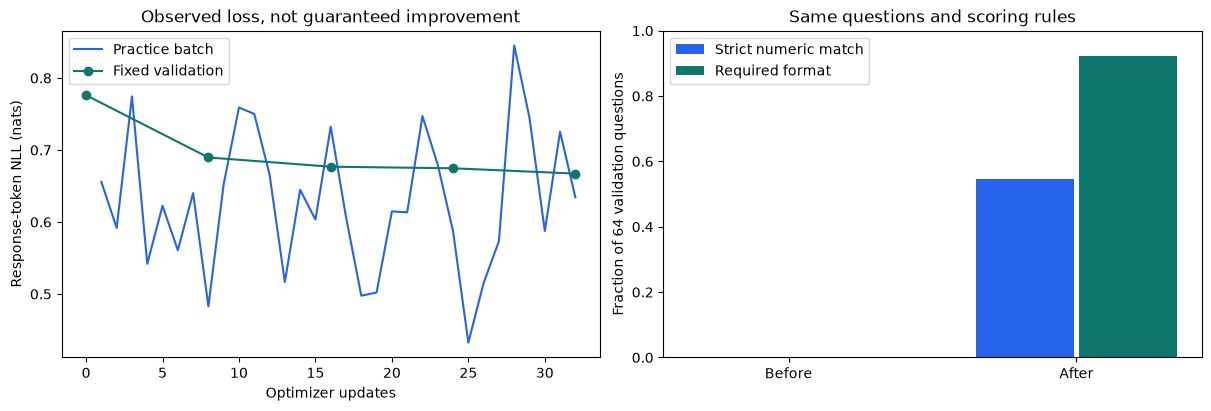

In [9]:
# Plot only real measurements from this training run, never illustrative scores.
if MODE == "train":
    measured = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    training_points = measured.dropna(subset=["training_loss"])
    validation_points = measured.dropna(subset=["validation_loss"])
    axes[0].plot(training_points["step"], training_points["training_loss"], label="Practice batch", color="#2563EB")
    axes[0].plot(validation_points["step"], validation_points["validation_loss"], marker="o", label="Fixed validation", color="#0F766E")
    axes[0].set(xlabel="Optimizer updates", ylabel="Response-token NLL (nats)", title="Observed loss, not guaranteed improvement")
    axes[0].legend()
    pairs = comparison_rows[:2]
    for offset, field, label, color in [(-0.18, "strict_accuracy", "Strict numeric match", "#2563EB"),
                                        (0.18, "format_compliance", "Required format", "#0F766E")]:
        axes[1].bar([index + offset for index in range(2)], [row[field] for row in pairs], width=0.34, label=label, color=color)
    axes[1].set(xticks=[0, 1], xticklabels=["Before", "After"], ylim=(0, 1), ylabel="Fraction of 64 validation questions", title="Same questions and scoring rules")
    axes[1].legend()
    fig.savefig(run_directory / "observed_results.png", dpi=170)
    plt.show()
else:
    print("INSPECT: results chart awaits real training measurements.")

---
<a id="save"></a>
## 7. Save the checkpoint and the evidence

> **Goal:** Preserve something Notebook 04 can load, plus evidence another reader can audit.

The final checkpoint includes model weights, model configuration, tokenizer files,
and checksums. We reload it and compare logits on the same short prefix. This
checks that the saved model can be read back; it does not remeasure task accuracy.

The saved output below used the original check: vocabulary identity and model
logits. It emitted a tokenizer regex warning. The finalized helper now also checks
text encoding and decoding, including the selected prompts and reference answers.
A local tokenizer-only reproduction identified a Transformers 4.57.6 Mistral
warning on Qwen3; the helper disables that unrelated rewrite only after confirming
`model_type = "qwen3"`. It does not change Qwen's tokenization to a Mistral regex.
The stronger check has not been rerun against the actual Colab checkpoint here.
The checkpoint is for further training or inference, not for resuming AdamW
mid-epoch because optimizer state is intentionally not included.

The **report ZIP** contains exact split records and training labels, configuration,
raw evaluation responses and token IDs, both checker results, training logs,
source code, runtime details, and checksums. The **checkpoint ZIP** is separate:
FP32 weights for a 0.6B model are roughly 2.4 GB before packaging. System RAM,
GPU memory, and disk space are different resources. Keep enough disk space for
both the saved folder and its ZIP.

In [10]:
# Keep full model weights separate from the lightweight, checksummed evidence report.
# Reload the saved checkpoint before declaring the run complete.
if MODE == "train":
    checkpoint_directory = run_directory / "checkpoint"
    save_checkpoint(student, tokenizer, checkpoint_directory)
    checkpoint_verified = verify_checkpoint(student, tokenizer, checkpoint_directory,
                                             validation_examples[0]["input_ids"], device, compute_dtype,
        probe_texts=[text for record in train_examples + validation_examples
                     for text in (record["prompt"], record["target_text"])]
                    + [record["prompt"] for record in protocol["examples"]])
    runtime = {"kind": "real_student_cuda_training", "gpu": torch.cuda.get_device_name(0),
               "torch": torch.__version__, "cuda": torch.version.cuda,
               "huggingface_packages": {name: importlib.metadata.version(name) for name in ["transformers", "datasets", "accelerate", "huggingface_hub"]},
               "parameter_dtype": "float32", "autocast_dtype": str(compute_dtype),
               "dataset_fingerprint": source_train._fingerprint, "dataset_revision": protocol["dataset_revision"],
               "optimizer_steps": step, "training_seconds": training_seconds,
               "peak_allocated_gpu_gib": torch.cuda.max_memory_allocated() / 2**30,
               "before_validation_loss": before_validation_loss, "after_validation_loss": after_validation_loss}
    report_archive = save_report(PROJECT_ROOT, run_directory, config, protocol, splits, history,
        {"before_validation": before_validation, "after_validation": after_validation, "final_test": final_test},
        runtime, checkpoint_verified)
    verified_manifest = verify_report(run_directory / "report")
    print("Checkpoint reload and report checksum tests passed.")
    print("Report ZIP:", report_archive)
    print("Checkpoint folder:", checkpoint_directory)
    print("For 04: AutoModelForCausalLM.from_pretrained(checkpoint_directory)")
else:
    print("INSPECT: no trained checkpoint or performance report exported.")

The tokenizer you are loading from '/content/on-policy-distillation/results/sft_cold_start_20261102T214504764023Z/checkpoint' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Checkpoint reload and report checksum tests passed.
Report ZIP: /content/on-policy-distillation/results/sft_cold_start_20261102T214504764023Z/report.zip
Checkpoint folder: /content/on-policy-distillation/results/sft_cold_start_20261102T214504764023Z/checkpoint
For 04: AutoModelForCausalLM.from_pretrained(checkpoint_directory)


### 7.1 Download before Colab disconnects

A path under `/content/` is on the Colab server, not in your computer's Downloads
folder. The next cell downloads the lightweight report by default after training.
Set `DOWNLOAD_CHECKPOINT = True` to create and download the separate, large weight
archive too. In a VS Code Colab connection, browser downloads may require opening
Colab's browser interface. No Google Drive or Hugging Face upload is performed.

For Notebook 04, upload and extract the checkpoint ZIP into its runtime and point
its model-loading code at the extracted folder. Running Notebook 03 again is not
required merely to use its saved checkpoint.

In [11]:
# Report and weights have separate switches so a small report download does not
# unexpectedly trigger a multi-gigabyte transfer. Both artifacts stay local/server-side.
DOWNLOAD_REPORT = True
DOWNLOAD_CHECKPOINT = False
if MODE == "train":
    checkpoint_archive = None
    if DOWNLOAD_CHECKPOINT:
        checkpoint_archive = Path(shutil.make_archive(str(run_directory / "checkpoint"), "zip", root_dir=checkpoint_directory))
    if IN_COLAB:
        from google.colab import files
        if DOWNLOAD_REPORT:
            files.download(str(report_archive))
        if checkpoint_archive is not None:
            files.download(str(checkpoint_archive))
    else:
        print("Download/copy the files from:", run_directory)
else:
    print("Inspection complete. No weights trained, no results invented, and no downloads requested.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### What we achieved, in simple terms

We prepared separate practice and validation questions and checked exactly which
parts of each worked solution the student should learn. The prompt remains
context; only the response and its real end token contribute to the loss.

**In inspection mode**, we verified data preparation and token alignment. We have
not measured the pretrained student's probabilities or changed any weights.

**After a successful training-mode run**, we have taken the original student
through a small supervised lesson, compared its validation behavior before and
after, measured the reserved test subset once, and saved a reloadable checkpoint.
The actual scores and loss curves determine what changed. A valid pipeline is
not a promise of better reasoning.

The teacher has not been used. This is still **supervised learning from existing
solutions**, not on-policy distillation. Notebook 04 will start from the saved
student checkpoint, let that student write responses, and use frozen teacher
feedback on those exact response tokens and prefixes.

### What we achieved across 01, 02, and 03

Think of the project as **check the teaching machinery → give a starting test →
provide a short lesson**.

| Notebook | In simple terms | What the evidence supports |
| :--- | :--- | :--- |
| **01: Check the machinery** | Let the student write one answer. Ask the teacher to score those exact tokens, compare probabilities, and test one weight update. | The mechanics work. The saved update increased KL, so this was not evidence of improved quality. |
| **02: Give a starting test** | Ask the unchanged student 32 math questions and keep its answers. Check formatting and numeric agreement separately. | Strict matches were 0/32 because no response used `####`. The exploratory prose checker found 17/32 numeric matches. |
| **03: Provide a short lesson** | Train the original student on 256 worked solutions, then check separate validation questions and save its weights. | The student learned the required format strongly. Mathematical reasoning results were mixed. |

For the **same 64 validation questions**, the saved 03 run shows:

| Measurement | Before the lesson | After the lesson |
| :--- | ---: | ---: |
| Required final-answer format | 0/64 | 59/64 |
| Strict numeric matches | 0/64 | 35/64 |
| Exploratory prose numeric matches | 31/64 | 35/64 |
| Reference-response loss, nats per target token | 0.776 | 0.667 |
| Responses reaching the 512-token limit | 0/64 | 5/64 |

**How to read this:** the large strict-score increase includes learning the
format. The prose checker found four additional matching answers, a smaller gain.
The five new token-limit stops need inspection; lower reference-token loss does
not guarantee shorter or better independent answers.

The displayed watermelon example makes the limit concrete. Before training, the
student correctly calculated **10 customers**. After training, it mixed up customer
and watermelon counts and wrote **`#### 26`**. It followed the format but got the
reasoning wrong. That regression remains visible rather than being edited away.

On the reserved 32-question test subset, the final student obtained **14/32 strict
matches**, **32/32 format compliance**, and **13/32 exploratory prose matches**.
The historical 02 prose score was 17/32 under different execution provenance.
These small results do not establish a broad reasoning improvement.

**Where we are now:** we have working distillation mechanics, an inspectable
baseline, and a supervised starting checkpoint. We have not yet shown that
on-policy distillation improves the student. That is the experiment for 04.

**What is preserved:** the code and these observed A100 outputs are stored locally
and versioned. The report and full checkpoint were created on Colab; neither is
currently present in this local checkout. A saved notebook is not a backup of the
model weights. Download and retain the report and checkpoint ZIP before Colab
storage disappears, then verify the tokenizer when loading that checkpoint in 04.

### Evidence and reproducibility

- Training, validation, and reserved test identities are preserved with the report.
- The original 02 evidence and both extraction rules remain unchanged.
- No student weights, personal credentials, or large checkpoints are committed to Git.
- [Local validation record](assets/03_sft_cold_start/VALIDATION.md) distinguishes
  CPU tests/inspection from real Colab model training.
- Tests use a **tiny randomly initialized model** to check gradients and checkpoint
  reload. That test model is not the pretrained 0.6B student and is not a task result.

### References

- [GKD paper, Sections 4.3 and Appendix A.4](https://arxiv.org/html/2306.13649v3#S4.SS3): supervised starting points and the original arithmetic experiment.
- [GSM8K](https://huggingface.co/datasets/openai/gsm8k): reference questions and worked solutions, MIT licensed.
- [Qwen3 causal language model](https://huggingface.co/docs/transformers/v4.57.1/en/model_doc/qwen3): model inputs and labels.
- [Cross-entropy and ignored targets](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html): the response-only loss.
- [Reusable SFT helpers](../src/sft.py) · [CPU tests](../tests/test_sft.py) · [Back to the project](../README.md)